# Notebook B1: Hamiltonian là "bảng giá trị", và mô phỏng quá trình quantum annealing

Đi kèm [B-02: Hamiltonian và quantum annealing](../../docs/B-extensions/02-hamiltonian-and-annealing.md).

Hai việc: (1) thấy tận mắt rằng Hamiltonian của bài toán $H_P$ chỉ là một ma trận đường chéo chứa các giá trị của hàm mục tiêu; (2) mô phỏng chính xác quá trình ủ $H(s) = (1-s)H_0 + sH_P$ cho bài toán của Ví dụ 10 (3 qubit, nghiệm tối ưu duy nhất), để thấy vai trò của *energy gap* và thời gian ủ $T$.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
sys.path.insert(0, "../../code")
from qco_utils import cost_vector

f_poly = {frozenset(): -9, frozenset({0}): 13, frozenset({1}): 14, frozenset({2}): 9,
          frozenset({0, 1}): -18, frozenset({0, 2}): -18, frozenset({1, 2}): -18, frozenset({0, 1, 2}): 36}

cost = cost_vector(f_poly, 3)

## 1. $H_P$ là bảng giá trị của hàm mục tiêu

Với 3 biến nhị phân có $2^3 = 8$ lời giải. Hamiltonian $H_P$ là ma trận $8 \times 8$ đường chéo, phần tử thứ $i$ là $f(x)$ của lời giải thứ $i$. Cùng bảng đó có thể viết bằng toán tử Pauli-Z, như phương trình (43): $H_P = -2Z_1 - \tfrac{5}{2}Z_2 - \tfrac{9}{2}Z_1Z_2Z_3$.

In [2]:
Z = np.diag([1.0, -1.0]); I2 = np.eye(2)
def on(qubit_ops):                      # qubit 0 = bit ít quan trọng nhất (như Qiskit)
    out = np.array([[1.0]])
    for m in reversed(qubit_ops):
        out = np.kron(out, m)
    return out

HP_pauli = -2*on([Z, I2, I2]) - 2.5*on([I2, Z, I2]) - 4.5*on([Z, Z, Z])
print("H_P (Pauli) có đường chéo trùng bảng f(x):", np.allclose(np.diag(HP_pauli), cost),
      "| ngoài đường chéo bằng 0:", np.allclose(HP_pauli, np.diag(np.diag(HP_pauli))))
print()
print(" i | x1 x2 x3 |  f(x)")
for i in range(8):
    x = [(i >> j) & 1 for j in range(3)]
    print(f" {i} |  {x[0]}  {x[1]}  {x[2]} | {cost[i]:5.0f}")

H_P (Pauli) có đường chéo trùng bảng f(x): True | ngoài đường chéo bằng 0: True

 i | x1 x2 x3 |  f(x)
 0 |  0  0  0 |    -9
 1 |  1  0  0 |     4
 2 |  0  1  0 |     5
 3 |  1  1  0 |     0
 4 |  0  0  1 |     0
 5 |  1  0  1 |    -5
 6 |  0  1  1 |    -4
 7 |  1  1  1 |     9


Điều này giải thích vì sao các cổng Pauli-Z là then chốt: chúng đường chéo trong computational basis, nên tổng và tích của chúng sinh ra đúng các Hamiltonian có dạng "bảng giá trị". Bài toán tối ưu trở thành: *tìm trạng thái có năng lượng thấp nhất của một ma trận đường chéo đã biết trước*. Nếu ta được phép đọc cả bảng thì việc này tầm thường; khó khăn là bảng có $2^n$ dòng.

## 2. Phổ năng lượng của $H(s) = (1-s)H_0 + sH_P$

$H_0 = -\sum_j X_j$ có ground state là superposition đều $|{+}{+}{+}\rangle$ (dễ chuẩn bị). Khi $s$ tăng từ 0 đến 1, $H(s)$ đi từ $H_0$ đến $H_P$. Ta vẽ 8 mức năng lượng và tìm *energy gap* nhỏ nhất giữa mức thấp nhất và mức kế tiếp.

energy gap nhỏ nhất = 1.148 tại s = 0.258   (gap ở s = 1: 4.0)


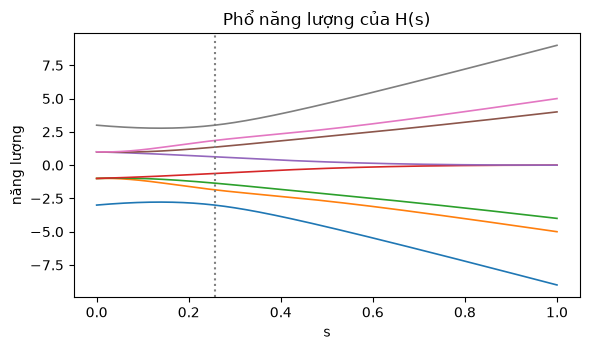

In [3]:
X = np.array([[0.0, 1.0], [1.0, 0.0]])
H0 = -sum(on([X if j == q else I2 for j in range(3)]) for q in range(3))
HP = np.diag(cost)

ss = np.linspace(0, 1, 401)
levels = np.array([np.linalg.eigvalsh((1 - s) * H0 + s * HP) for s in ss])
gap = levels[:, 1] - levels[:, 0]
k = gap.argmin()
print(f"energy gap nhỏ nhất = {gap[k]:.3f} tại s = {ss[k]:.3f}   (gap ở s = 1: {gap[-1]:.1f})")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(ss, levels, lw=1.2)
ax.axvline(ss[k], ls=":", c="gray")
ax.set_xlabel("s"); ax.set_ylabel("năng lượng"); ax.set_title("Phổ năng lượng của H(s)")
plt.tight_layout(); plt.show()

## 3. Xác suất đo được nghiệm tối ưu theo thời gian ủ $T$

Ta tiến hóa $|\psi\rangle$ dưới $H(s)$ với $s = t/T$, rồi tính xác suất ở trạng thái $|000\rangle$ (nghiệm tối ưu, $f = -9$). $T$ nhỏ là ủ quá nhanh (không còn đoạn nhiệt); $T$ lớn thì hệ đi theo ground state.

   T   P(000)   E trung bình
 0.25   0.146     -0.67
 0.50   0.191     -2.06
 1.00   0.259     -3.87
 2.00   0.371     -5.34
 4.00   0.586     -6.86
 8.00   0.874     -8.42
16.00   0.986     -8.93
32.00   0.999     -9.00
64.00   1.000     -9.00
tham chiếu: chọn ngẫu nhiên đều cho P = 0.125 và E = 0


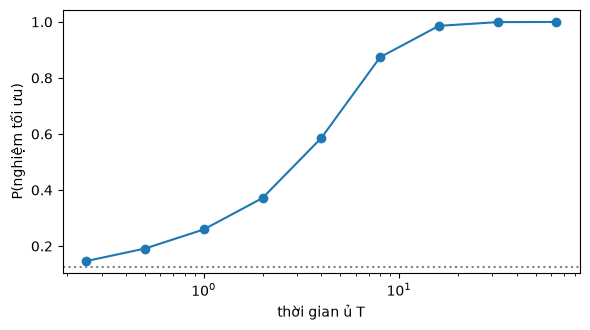

In [4]:
def anneal(T, per_unit=60, min_steps=300):
    N = max(min_steps, int(T * per_unit)); dt = T / N
    psi = np.ones(8, complex) / np.sqrt(8)
    for step in range(N):
        s = (step + 0.5) / N
        w, V = eigh((1 - s) * H0 + s * HP)
        psi = V @ (np.exp(-1j * w * dt) * (V.conj().T @ psi))
    return np.abs(psi) ** 2

Ts = [0.25, 0.5, 1, 2, 4, 8, 16, 32, 64]
rows = []
for T in Ts:
    p = anneal(T)
    rows.append((T, p[0], p @ cost))
print("   T   P(000)   E trung bình")
for T, p0, e in rows:
    print(f"{T:5.2f}  {p0:6.3f}   {e:7.2f}")
print("tham chiếu: chọn ngẫu nhiên đều cho P = 0.125 và E = 0")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.semilogx([r[0] for r in rows], [r[1] for r in rows], "o-")
ax.axhline(1/8, ls=":", c="gray"); ax.set_xlabel("thời gian ủ T"); ax.set_ylabel("P(nghiệm tối ưu)")
plt.tight_layout(); plt.show()

Quan sát:

- Với $T$ rất nhỏ, xác suất chỉ cao hơn ngẫu nhiên (0,125) một chút. Với $T$ vừa phải đã khá tốt dù chưa "đoạn nhiệt" thực sự. Điều này khớp với ghi chú ở Mục 2.2: quantum annealer *không bắt buộc* phải ở ground state suốt quá trình.
- Xác suất đạt gần 1 khi $T$ cỡ hàng chục lần nghịch đảo của gap nhỏ nhất (ở đây gap nhỏ nhất khoảng 1,15). Đây là nội dung thực tế của adiabatic theorem: bài toán nào có gap nhỏ nhất đóng nhanh theo kích thước thì cần $T$ rất lớn.
- Giá trị tuyệt đối của $T$ chỉ có nghĩa trong đơn vị năng lượng đang dùng: nếu nhân **cả** $H_0$ **và** $H_P$ với cùng một hằng số $\lambda$ thì kết quả giống hệt việc nhân $T$ với $\lambda$ (chỉ tích năng lượng × thời gian mới quan trọng). Vì thế khi so sánh các máy hay các bài toán, phải so $T$ theo cùng thang năng lượng.